In [ ]:
# Step 9: Statistical Analysis:

In [1]:
# Install the required Python libraries
!pip install pandas numpy matplotlib seaborn scipy sqlalchemy pymysql

In [2]:
# Import libraries and connect to MySQL
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
from statsmodels.formula.api import ols
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sns.set_theme(style="whitegrid")

ALPHA = 0.05
results = {}

# MySQL connection details
USER = "root"
PASSWORD = quote_plus("Arul@nitha08")
HOST = "localhost"
PORT = 3306
DB_NAME = "olist_db"

engine = create_engine(
    f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}"
)

def run_query(query):
    with engine.connect() as connection:
        return pd.read_sql(text(query), connection)

# Test the connection
print(run_query("SELECT COUNT(*) AS total_orders FROM orders"))

   total_orders
0         99441


In [ ]:
# Step 9: Statistical Analysis

In [3]:
# Part A — Independent two-sample T-test
# Load delivery status and review scores
query1 = """
SELECT
    o.order_id,
    AVG(r.review_score) AS review_score,
    CASE
        WHEN o.order_delivered_customer_date >
             o.order_estimated_delivery_date
        THEN 'Delayed'
        ELSE 'On Time'
    END AS delivery_status
FROM orders o
JOIN order_reviews r
    ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY
    o.order_id,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date
"""

df1 = run_query(query1)

df1["review_score"] = df1["review_score"].astype(float)

print("Dataset shape:", df1.shape)
display(df1.head())

Dataset shape: (95820, 3)


,order_id,review_score,delivery_status
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,On Time
1,00018f77f2f0320c557190d7a144bdd3,4.0,On Time
2,000229ec398224ef6ca0657da4fc703e,5.0,On Time
3,00024acbcdf0a6daa1e931b038114c75,4.0,On Time
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,On Time


In [ ]:
# Purpose: Retrieve delivered orders with review scores and classify them as delayed or on time.

In [ ]:
# Define hypotheses and examine the data
"""
H₀: Delayed orders do not have a lower mean review score than on-time orders.
H₁: Delayed orders have a lower mean review score than on-time orders.
"""

In [4]:
delayed = df1.loc[
    df1["delivery_status"] == "Delayed", "review_score"
].dropna()

ontime = df1.loc[
    df1["delivery_status"] == "On Time", "review_score"
].dropna()

print("Review score summary:")
display(
    df1.groupby("delivery_status")["review_score"]
       .agg(["count", "mean", "median", "std"])
       .round(3)
)

print("Delayed sample size:", len(delayed))
print("On-time sample size:", len(ontime))

Review score summary:


,count,mean,median,std
delivery_status,,,,
Delayed,7661,2.565,2.0,1.658
On Time,88159,4.294,5.0,1.147


Delayed sample size: 7661
On-time sample size: 88159


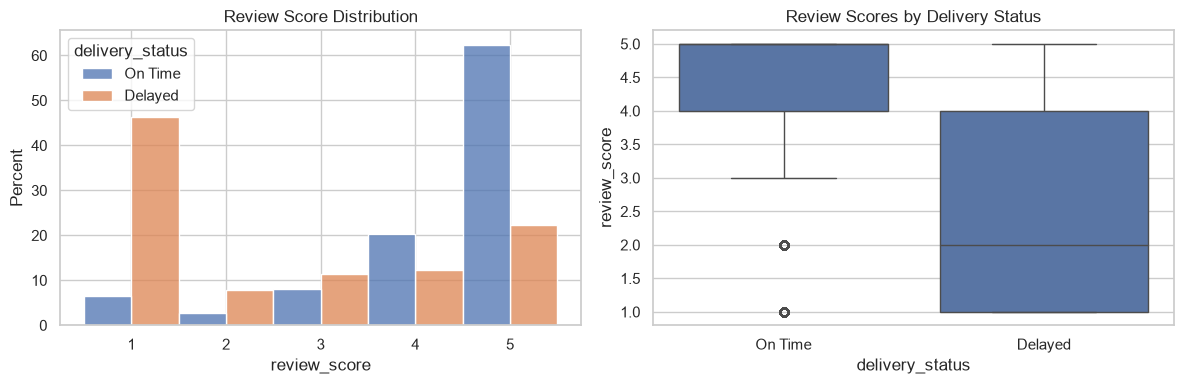

In [5]:
# Visualize the review scores
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df1,
    x="review_score",
    hue="delivery_status",
    discrete=True,
    stat="percent",
    common_norm=False,
    multiple="dodge",
    ax=ax[0]
)
ax[0].set_title("Review Score Distribution")

sns.boxplot(
    data=df1,
    x="delivery_status",
    y="review_score",
    ax=ax[1]
)
ax[1].set_title("Review Scores by Delivery Status")

plt.tight_layout()
plt.show()

In [6]:
# Check the equal-variance assumption
if len(delayed) < 2 or len(ontime) < 2:
    raise ValueError("Each delivery group needs at least two observations.")

lev_stat, lev_p = stats.levene(delayed, ontime)

print(f"Levene statistic: {lev_stat:.3f}")
print(f"Levene p-value: {lev_p:.4g}")

if lev_p < ALPHA:
    print("Evidence of unequal variances. Welch's t-test is appropriate.")
else:
    print("No strong evidence of unequal variances.")

Levene statistic: 3381.702
Levene p-value: 0
Evidence of unequal variances. Welch's t-test is appropriate.


In [ ]:
# Welch's t-test is used in the next cell regardless of the Levene result, so you do not need to change the test manually.

In [7]:
# Perform the T-test and calculate Cohen's d
# Welch's independent two-sample t-test
t_stat, p_val = stats.ttest_ind(
    delayed,
    ontime,
    equal_var=False,
    alternative="less"
)

# Difference in average scores
mean_delayed = delayed.mean()
mean_ontime = ontime.mean()
mean_difference = mean_delayed - mean_ontime

# Cohen's d (descriptive effect size)
pooled_sd = np.sqrt(
    (
        delayed.var(ddof=1) +
        ontime.var(ddof=1)
    ) / 2
)

cohen_d = (
    mean_difference / pooled_sd
    if pooled_sd > 0 else np.nan
)

# Non-parametric robustness check
u_stat, u_p = stats.mannwhitneyu(
    delayed,
    ontime,
    alternative="less"
)

print(f"Mean score - Delayed: {mean_delayed:.3f}")
print(f"Mean score - On Time: {mean_ontime:.3f}")
print(f"Mean difference: {mean_difference:.3f}")
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.6g}")
print(f"Cohen's d: {cohen_d:.3f}")
print(f"Mann-Whitney p-value: {u_p:.6g}")

if p_val < ALPHA:
    decision = "Reject H0"
    print("\nDecision: Statistically significant evidence.")
    print("Delayed orders have lower average review scores.")
else:
    decision = "Fail to reject H0"
    print("\nDecision: Insufficient evidence that delayed orders")
    print("have lower average review scores.")

if np.isnan(cohen_d):
    effect_size = "Undefined"
else:
    d = abs(cohen_d)
    effect_size = (
        "Negligible" if d < 0.2 else
        "Small" if d < 0.5 else
        "Medium" if d < 0.8 else
        "Large"
    )

print("Effect size interpretation:", effect_size)

results["T-Test"] = {
    "Statistic": round(t_stat, 3),
    "P-Value": p_val,
    "Effect Size": f"Cohen's d = {cohen_d:.3f}",
    "Decision": decision
}

Mean score - Delayed: 2.565
Mean score - On Time: 4.294
Mean difference: -1.729
T-statistic: -89.413
P-value: 0
Cohen's d: -1.213
Mann-Whitney p-value: 0

Decision: Statistically significant evidence.
Delayed orders have lower average review scores.
Effect size interpretation: Large


In [8]:
# T-test business conclusion
if p_val < ALPHA:
    print(
        f"Business conclusion: Delayed orders received lower average "
        f"review scores ({mean_delayed:.2f}) than on-time orders "
        f"({mean_ontime:.2f}). The difference was statistically "
        f"significant (p={p_val:.4g}). The business should investigate "
        f"delivery delays and improve delivery reliability."
    )
else:
    print(
        f"Business conclusion: The analysis did not find sufficient "
        f"evidence that delayed orders receive lower average review "
        f"scores (p={p_val:.4g}). Other factors affecting customer "
        f"satisfaction should also be investigated."
    )

Business conclusion: Delayed orders received lower average review scores (2.57) than on-time orders (4.29). The difference was statistically significant (p=0). The business should investigate delivery delays and improve delivery reliability.


In [ ]:
# Part B — One-way ANOVA

In [ ]:
# Load product category and order value
"""
Hypotheses
- H₀: All included product categories have equal mean log order values.
- H₁: At least one category has a different mean log order value.
"""

In [9]:
query2 = """
SELECT
    oi.order_id,
    MIN(t.product_category_name_english) AS category,
    SUM(oi.price + oi.freight_value) AS order_value
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
JOIN product_category_name_translation t
    ON p.product_category_name = t.product_category_name
GROUP BY oi.order_id
HAVING COUNT(DISTINCT p.product_category_name) = 1
"""

df2 = run_query(query2)

df2["order_value"] = pd.to_numeric(
    df2["order_value"], errors="coerce"
)

df2 = df2.dropna(subset=["category", "order_value"])
df2 = df2[df2["order_value"] >= 0].copy()

# Keep categories with at least 30 orders
category_counts = df2["category"].value_counts()
valid_categories = category_counts[
    category_counts >= 30
].index

df2 = df2[
    df2["category"].isin(valid_categories)
].copy()

# Log transformation to reduce right skew
df2["log_value"] = np.log1p(df2["order_value"])

print("Orders analyzed:", len(df2))
print("Categories analyzed:", df2["category"].nunique())

display(df2.head())

Orders analyzed: 96377
Categories analyzed: 62


,order_id,category,order_value,log_value
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,72.19,4.293059
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,259.83,5.563869
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,216.87,5.383899
3,00024acbcdf0a6daa1e931b038114c75,perfumery,25.78,3.287655
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools,218.04,5.389254


In [ ]:
# This query uses only single-category orders. The results will apply to this subset, not necessarily all orders.

Raw order-value skewness: 9.306
Log-value skewness: 0.554


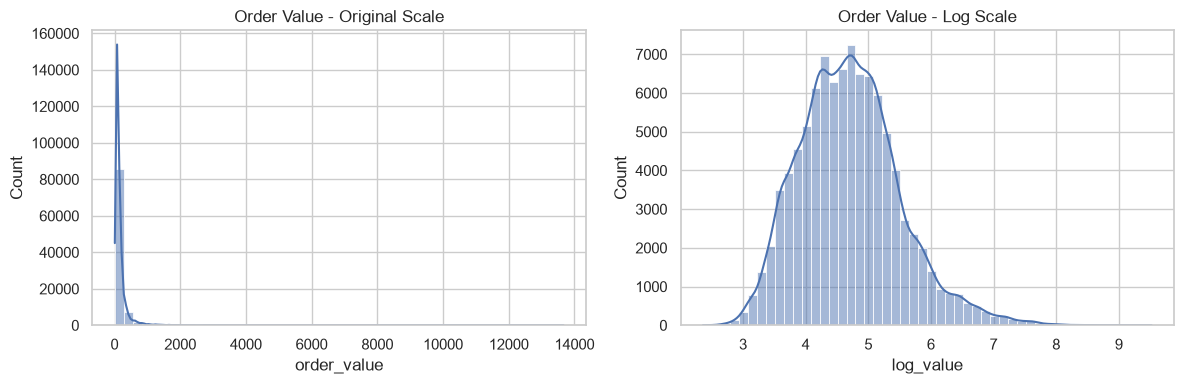

,count,mean,median,std
category,,,,
computers,180,1285.52,1250.81,738.95
small_appliances_home_oven_and_coffee,75,669.25,673.47,629.51
home_appliances_2,233,530.98,287.27,560.65
agro_industry_and_commerce,182,430.63,410.62,616.05
musical_instruments,621,337.21,143.83,486.24
small_appliances,624,328.69,128.27,508.90
fixed_telephony,215,297.67,74.59,1101.66
office_furniture,1258,269.60,206.21,216.13
construction_tools_safety,160,269.22,164.60,382.60


In [10]:
# Explore the order-value distribution
print("Raw order-value skewness:", round(df2["order_value"].skew(), 3))
print("Log-value skewness:", round(df2["log_value"].skew(), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df2["order_value"],
    bins=50,
    kde=True,
    ax=ax[0]
)
ax[0].set_title("Order Value - Original Scale")

sns.histplot(
    df2["log_value"],
    bins=50,
    kde=True,
    ax=ax[1]
)
ax[1].set_title("Order Value - Log Scale")

plt.tight_layout()
plt.show()

category_summary = (
    df2.groupby("category")["order_value"]
       .agg(["count", "mean", "median", "std"])
       .sort_values("mean", ascending=False)
       .round(2)
)

display(category_summary.head(10))

In [ ]:
# The original-scale summary helps explain spending in currency units. The statistical ANOVA below uses log_value.

In [11]:
# Check the equal-variance assumption
groups = [
    group["log_value"].to_numpy()
    for _, group in df2.groupby("category")
]

if len(groups) < 2:
    raise ValueError("ANOVA requires at least two categories.")

if any(len(group) < 2 for group in groups):
    raise ValueError("Each category needs at least two observations.")

lev_stat, lev_p = stats.levene(*groups)

print(f"Levene statistic: {lev_stat:.3f}")
print(f"Levene p-value: {lev_p:.4g}")

if lev_p < ALPHA:
    print(
        "Evidence of unequal variances. Interpret classical ANOVA "
        "carefully and consider Welch's ANOVA."
    )
else:
    print("No strong evidence of unequal variances.")

Levene statistic: 52.501
Levene p-value: 0
Evidence of unequal variances. Interpret classical ANOVA carefully and consider Welch's ANOVA.


In [12]:
# Perform ANOVA and calculate eta-squared
# Classical one-way ANOVA on log-transformed values
F_stat, p_val = stats.f_oneway(*groups)

# Calculate eta-squared using an ANOVA model
model = ols(
    "log_value ~ C(category)",
    data=df2
).fit()

anova_table = sm.stats.anova_lm(model, typ=2)

eta_sq = (
    anova_table.loc["C(category)", "sum_sq"]
    / anova_table["sum_sq"].sum()
)

# Kruskal-Wallis robustness comparison
H_stat, kw_p = stats.kruskal(*groups)

print(f"F-statistic: {F_stat:.3f}")
print(f"ANOVA p-value: {p_val:.6g}")
print(f"Eta-squared: {eta_sq:.4f}")
print(f"Kruskal-Wallis statistic: {H_stat:.3f}")
print(f"Kruskal-Wallis p-value: {kw_p:.6g}")

if p_val < ALPHA:
    decision = "Reject H0"
    print("\nDecision: At least one category mean differs significantly.")
else:
    decision = "Fail to reject H0"
    print("\nDecision: Insufficient evidence of different category means.")

eta_size = (
    "Small" if eta_sq < 0.06 else
    "Medium" if eta_sq < 0.14 else
    "Large"
)

print("Eta-squared effect-size guideline:", eta_size)

results["ANOVA"] = {
    "Statistic": round(F_stat, 3),
    "P-Value": p_val,
    "Effect Size": f"Eta-squared = {eta_sq:.4f}",
    "Decision": decision
}

F-statistic: 222.467
ANOVA p-value: 0
Eta-squared: 0.1235
Kruskal-Wallis statistic: 11410.832
Kruskal-Wallis p-value: 0

Decision: At least one category mean differs significantly.
Eta-squared effect-size guideline: Medium


In [ ]:
"""
Eta-squared describes the proportion of variation in the analyzed log-transformed values explained by category in this model. 
The small/medium/large labels are rough guidelines, not universal rules.
"""

In [ ]:
# Welch's ANOVA (recommended when variances differ)
# This optional test is especially useful if Levene's test indicates unequal variances.

In [15]:
# Install pingouin
!pip install pingouin


   -------------------- ------------------- 1/2 [pingouin]
   -------------------- ------------------- 1/2 [pingouin]
   ---------------------------------------- 2/2 [pingouin]



In [18]:

import pingouin as pg

welch_result = pg.welch_anova(
    data=df2,
    dv="log_value",
    between="category"
)

display(welch_result)

print("Available columns:")
print(welch_result.columns.tolist())

,Source,ddof1,ddof2,F,p_unc,np2
0,category,61,3720.154002,263.50675,0.0,0.123497


Available columns:
['Source', 'ddof1', 'ddof2', 'F', 'p_unc', 'np2']


In [19]:
# Replace your existing code with this corrected version
# This version checks the available column names instead of assuming the p-value column is always named p-unc.

try:
    import pingouin as pg

    welch_result = pg.welch_anova(
        data=df2,
        dv="log_value",
        between="category"
    )

    display(welch_result)

    # Find the p-value column
    possible_columns = ["p-unc", "p_unc", "pval", "p-value"]
    p_column = next(
        (col for col in possible_columns
         if col in welch_result.columns),
        None
    )

    if p_column is None:
        print("Could not identify the p-value column.")
        print("Available columns:", welch_result.columns.tolist())
    else:
        welch_p = float(welch_result[p_column].iloc[0])

        print(f"Welch ANOVA p-value: {welch_p:.6g}")

        if welch_p < ALPHA:
            print(
                "Decision: Reject H0. There is evidence that "
                "at least one category mean differs."
            )
        else:
            print(
                "Decision: Fail to reject H0. There is insufficient "
                "evidence of differences in category means."
            )

except ImportError:
    print(
        "Pingouin is not installed. Run %pip install pingouin "
        "in a separate notebook cell, then rerun this cell."
    )


,Source,ddof1,ddof2,F,p_unc,np2
0,category,61,3720.154002,263.50675,0.0,0.123497


Welch ANOVA p-value: 0
Decision: Reject H0. There is evidence that at least one category mean differs.


In [ ]:
"""
1. Understanding your results
Result	Value	Simple meaning
F-statistic	263.50675	The category means differ substantially relative to within-category variation.
Degrees of freedom (ddof1)	61	I am comparing 62 product categories.
Degrees of freedom (ddof2)	3720.154	Adjusted degrees of freedom for Welch ANOVA.
P-value (p_unc)	0.0	The p-value is too small to display at the shown precision.
Effect size (np2)	0.123497	The reported effect-size estimate is about 12.35%.
"""

In [ ]:
"""
What is the conclusion?
My hypotheses are:
- Null hypothesis (H₀): All product categories have the same mean log-transformed order value.
- Alternative hypothesis (H₁): At least one product category has a different mean log-transformed order value.
Using a significance level of \(\alpha = 0.05\):
Decision: Reject H₀.
Your results provide strong statistical evidence that the mean log-transformed order value differs across at least some product categories. 
This does not mean every category differs from every other category.
Also, p_unc = 0.0 does not mean the true p-value is exactly zero. It means the value is extremely small or rounded to zero in the displayed output.
"""

In [ ]:
# Tukey HSD post-hoc test
"""
Run this after ANOVA when you want to find out which category pairs differ. 
This code compares the ten most frequent categories, using the log-transformed values.
"""

In [20]:
top10 = df2["category"].value_counts().head(10).index

df_top10 = df2[
    df2["category"].isin(top10)
].copy()

tukey = pairwise_tukeyhsd(
    endog=df_top10["log_value"],
    groups=df_top10["category"],
    alpha=ALPHA
)

tukey_df = pd.DataFrame(
    tukey.summary().data[1:],
    columns=tukey.summary().data[0]
)

print("Tukey HSD results:")
display(tukey_df)

significant_pairs = tukey_df[
    tukey_df["reject"] == True
]

print("Number of significant category pairs:", len(significant_pairs))
display(significant_pairs)

Tukey HSD results:


,group1,group2,meandiff,p-adj,lower,upper,reject
0,auto,bed_bath_table,-0.0389,0.1659,-0.0842,0.0064,False
1,auto,computers_accessories,-0.0256,0.8001,-0.0734,0.0222,False
2,auto,furniture_decor,-0.0246,0.8427,-0.0730,0.0237,False
3,auto,health_beauty,-0.0114,0.9987,-0.0571,0.0342,False
4,auto,housewares,-0.1682,0.0000,-0.2173,-0.1191,True
5,auto,sports_leisure,-0.0194,0.9495,-0.0661,0.0272,False
6,auto,telephony,-0.6223,0.0000,-0.6750,-0.5695,True
7,auto,toys,-0.0219,0.9563,-0.0758,0.0319,False
8,auto,watches_gifts,0.3607,0.0000,0.3113,0.4102,True
9,bed_bath_table,computers_accessories,0.0133,0.9839,-0.0247,0.0514,False


Number of significant category pairs: 24


,group1,group2,meandiff,p-adj,lower,upper,reject
4,auto,housewares,-0.1682,0.0,-0.2173,-0.1191,True
6,auto,telephony,-0.6223,0.0,-0.6750,-0.5695,True
8,auto,watches_gifts,0.3607,0.0,0.3113,0.4102,True
12,bed_bath_table,housewares,-0.1293,0.0,-0.1689,-0.0897,True
14,bed_bath_table,telephony,-0.5834,0.0,-0.6274,-0.5393,True
16,bed_bath_table,watches_gifts,0.3997,0.0,0.3596,0.4397,True
19,computers_accessories,housewares,-0.1426,0.0,-0.1851,-0.1001,True
21,computers_accessories,telephony,-0.5967,0.0,-0.6434,-0.5500,True
23,computers_accessories,watches_gifts,0.3863,0.0,0.3434,0.4292,True
25,furniture_decor,housewares,-0.1436,0.0,-0.1867,-0.1005,True


In [ ]:
"""
Tukey HSD assumes the classical ANOVA variance conditions. 
If variances differ, use a suitable post-hoc method for unequal variances, such as Games–Howell, instead.
"""

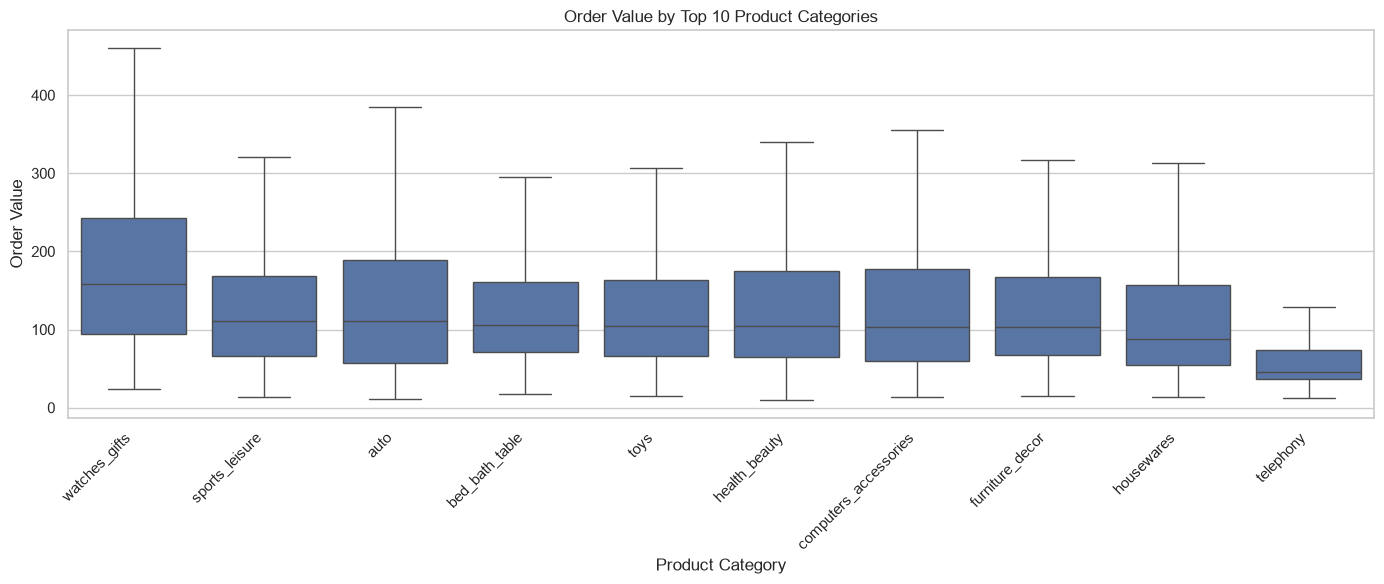

In [21]:
# Visualize category spending
category_order = (
    df_top10.groupby("category")["order_value"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_top10,
    x="category",
    y="order_value",
    order=category_order,
    showfliers=False
)

plt.title("Order Value by Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Order Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
"""
The boxplot displays original order values for easier business interpretation; 
the hypothesis test uses log-transformed values.
"""

In [22]:
# ANOVA business conclusion
if p_val < ALPHA:
    print(
        f"Business conclusion: Mean log order value differs significantly "
        f"across the included product categories (F={F_stat:.3f}, "
        f"p={p_val:.4g}, eta-squared={eta_sq:.4f}). "
        "Use the post-hoc results to identify which categories differ. "
        "These findings may help guide category-specific pricing, "
        "bundling, and upselling strategies."
    )
else:
    print(
        f"Business conclusion: There is insufficient evidence that "
        f"mean log order value differs across the included product "
        f"categories (p={p_val:.4g}). Avoid claiming significant "
        "category differences based on this test."
    )

Business conclusion: Mean log order value differs significantly across the included product categories (F=222.467, p=0, eta-squared=0.1235). Use the post-hoc results to identify which categories differ. These findings may help guide category-specific pricing, bundling, and upselling strategies.


In [ ]:
# Part C — Chi-square test of independence

In [ ]:
# Load payment method and order status
"""
Hypotheses
- H₀: Payment method and order status are independent.
- H₁: Payment method and order status are associated.
"""

In [23]:
query3 = """
SELECT
    o.order_id,
    p.payment_type,
    o.order_status
FROM orders o
JOIN order_payments p
    ON o.order_id = p.order_id
WHERE p.payment_sequential = 1
  AND p.payment_type <> 'not_defined'
"""

df3 = run_query(query3)

print("Dataset shape:", df3.shape)
print("\nOrder status counts:")
display(df3["order_status"].value_counts())

Dataset shape: (99357, 3)

Order status counts:


order_status
delivered      96399
shipped         1107
canceled         622
unavailable      608
invoiced         314
processing       300
created            5
approved           2
Name: count, dtype: int64

In [ ]:
"""
Using payment_sequential = 1 selects the primary payment record for each order, 
helping prevent duplicate counting when orders have multiple payment records.
"""

In [24]:
# Group rare order statuses and create a contingency table
df3["status_group"] = df3["order_status"].apply(
    lambda status:
        status if status in ["delivered", "canceled"]
        else "other"
)

ct = pd.crosstab(
    df3["payment_type"],
    df3["status_group"]
)

print("Observed counts:")
display(ct)

Observed counts:


status_group,canceled,delivered,other
payment_type,,,
boleto,95,19190,498
credit_card,444,74275,1757
debit_card,7,1436,34
voucher,76,1498,47


In [ ]:
# The table counts how many orders fall into each payment-method and order-status combination.

In [25]:
# Perform the Chi-square test and check assumptions
chi2, p_val, dof, expected = stats.chi2_contingency(ct)

expected_df = pd.DataFrame(
    expected,
    index=ct.index,
    columns=ct.columns
)

print("Expected counts under independence:")
display(expected_df.round(2))

percent_ok = (expected >= 5).mean() * 100
minimum_expected = expected.min()

print(f"Cells with expected counts >= 5: {percent_ok:.1f}%")
print(f"Minimum expected count: {minimum_expected:.2f}")

assumptions_met = (
    percent_ok >= 80 and minimum_expected >= 1
)

if assumptions_met:
    print("Expected-frequency assumption is satisfied.")
else:
    print(
        "Expected-frequency assumption is not satisfied. "
        "Review sparse categories before interpreting the test."
    )

Expected counts under independence:


status_group,canceled,delivered,other
payment_type,,,
boleto,123.85,19194.03,465.12
credit_card,478.76,74199.20,1798.04
debit_card,9.25,1433.03,34.73
voucher,10.15,1572.74,38.11


Cells with expected counts >= 5: 100.0%
Minimum expected count: 9.25
Expected-frequency assumption is satisfied.


In [ ]:
"""
Do not blindly combine categories simply to make the test significant. 
Any grouping should make business sense.
"""

In [26]:
# Calculate Cramér's V and make the decision
n = ct.to_numpy().sum()
min_dimension = min(ct.shape)

if min_dimension < 2:
    raise ValueError(
        "Chi-square independence testing requires at least "
        "two payment categories and two status categories."
    )

cramers_v = np.sqrt(
    chi2 / (n * (min_dimension - 1))
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_val:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")

if p_val < ALPHA:
    decision = "Reject H0"
    print(
        "\nDecision: Payment method and order status "
        "are statistically associated."
    )
else:
    decision = "Fail to reject H0"
    print(
        "\nDecision: Insufficient evidence of an association "
        "between payment method and order status."
    )

v_size = (
    "Negligible" if cramers_v < 0.1 else
    "Weak" if cramers_v < 0.3 else
    "Moderate" if cramers_v < 0.5 else
    "Strong"
)

print("Association strength (rough guideline):", v_size)

results["Chi-Square"] = {
    "Statistic": round(chi2, 3),
    "P-Value": p_val,
    "Effect Size": f"Cramer's V = {cramers_v:.4f}",
    "Decision": decision
}

Chi-square statistic: 446.105
Degrees of freedom: 6
P-value: 3.38233e-93
Cramer's V: 0.0474

Decision: Payment method and order status are statistically associated.
Association strength (rough guideline): Negligible


In [ ]:
# The strength labels are rough guidelines. Interpret Cramér's V in context, particularly with many categories.

Order status percentages by payment method:


status_group,canceled,delivered,other
payment_type,,,
boleto,0.48,97.00,2.52
credit_card,0.58,97.12,2.30
debit_card,0.47,97.22,2.30
voucher,4.69,92.41,2.90


Standardized residuals:


status_group,canceled,delivered,other
payment_type,,,
boleto,-2.59,-0.03,1.52
credit_card,-1.59,0.28,-0.97
debit_card,-0.74,0.08,-0.12
voucher,20.67,-1.88,1.44


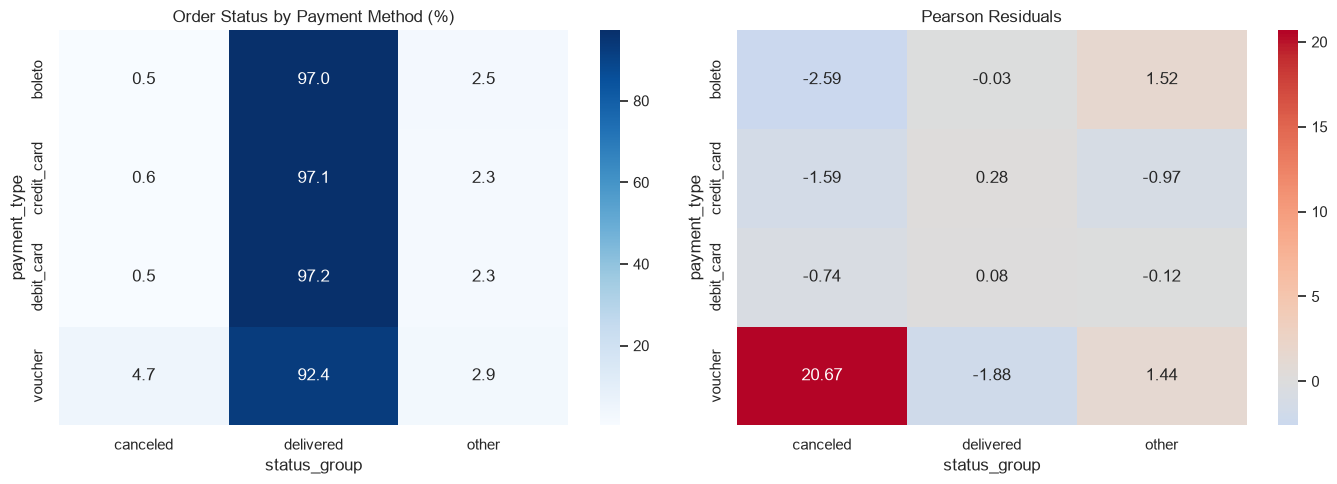

In [27]:
# Row percentages and standardized residuals
# Percentage of each order status within each payment method
row_percentages = (
    ct.div(ct.sum(axis=1), axis=0) * 100
).round(2)

print("Order status percentages by payment method:")
display(row_percentages)

# Standardized residuals (Pearson residuals)
residuals = (
    ct - expected_df
) / np.sqrt(expected_df)

print("Standardized residuals:")
display(residuals.round(2))

# Visualize percentages and residuals
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    row_percentages,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    ax=ax[0]
)
ax[0].set_title("Order Status by Payment Method (%)")

sns.heatmap(
    residuals,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax[1]
)
ax[1].set_title("Pearson Residuals")

plt.tight_layout()
plt.show()

In [ ]:
"""
Interpretation:
- Row percentages help you compare the order-status mix for each payment method.
- Positive residuals mean more orders were observed in a cell than expected under independence.
- Negative residuals mean fewer orders were observed than expected.
- Residuals are useful for exploration; formal claims about individual cells should account for multiple comparisons.
"""

In [28]:
# Chi-square business conclusion
if p_val < ALPHA:
    print(
        f"Business conclusion: Payment method and order status are "
        f"statistically associated (chi-square={chi2:.3f}, "
        f"p={p_val:.4g}). Cramer's V={cramers_v:.4f}, "
        f"indicating a {v_size.lower()} association by the selected "
        f"guideline. Review the status percentages to identify patterns "
        f"that may deserve further investigation."
    )
else:
    print(
        f"Business conclusion: The analysis did not find sufficient "
        f"evidence of an association between payment method and order "
        f"status (p={p_val:.4g}). Other factors may be worth investigating."
    )

Business conclusion: Payment method and order status are statistically associated (chi-square=446.105, p=3.382e-93). Cramer's V=0.0474, indicating a negligible association by the selected guideline. Review the status percentages to identify patterns that may deserve further investigation.


In [ ]:
# Part D — Final summary of all three tests

In [29]:
# Create the statistical results table
summary_df = pd.DataFrame(results).T

summary_df["P-Value"] = summary_df["P-Value"].apply(
    lambda p: "< 0.0001" if p < 0.0001 else f"{p:.4f}"
)

summary_df.index.name = "Statistical Test"

display(summary_df)

,Statistic,P-Value,Effect Size,Decision
Statistical Test,,,,
T-Test,-89.413,< 0.0001,Cohen's d = -1.213,Reject H0
ANOVA,222.467,< 0.0001,Eta-squared = 0.1235,Reject H0
Chi-Square,446.105,< 0.0001,Cramer's V = 0.0474,Reject H0


In [ ]:
"""
My final table will show:
- Test statistic
- P-value
- Effect size
- Statistical decision
"""

In [30]:
# Generate a combined project conclusion      
print("=" * 65)
print("STEP 9: STATISTICAL ANALYSIS - FINAL REPORT")
print("=" * 65)

# T-test conclusion
if results["T-Test"]["Decision"] == "Reject H0":
    print(
        "\n1. T-TEST: Significant evidence that delayed orders "
        "receive lower average review scores."
    )
else:
    print(
        "\n1. T-TEST: Insufficient evidence that delayed orders "
        "receive lower average review scores."
    )

# ANOVA conclusion
if results["ANOVA"]["Decision"] == "Reject H0":
    print(
        "\n2. ANOVA: Significant evidence that mean log order value "
        "differs across the included product categories."
    )
else:
    print(
        "\n2. ANOVA: Insufficient evidence of differences in mean "
        "log order value across the included product categories."
    )

# Chi-square conclusion
if results["Chi-Square"]["Decision"] == "Reject H0":
    print(
        "\n3. CHI-SQUARE: Significant evidence of an association "
        "between payment method and order status."
    )
else:
    print(
        "\n3. CHI-SQUARE: Insufficient evidence of an association "
        "between payment method and order status."
    )

print("\nLimitations:")
print("- These results show statistical associations, not causation.")
print("- Statistical significance does not automatically imply a large effect.")
print("- Conclusions apply to the records and groups included in each test.")

STEP 9: STATISTICAL ANALYSIS - FINAL REPORT

1. T-TEST: Significant evidence that delayed orders receive lower average review scores.

2. ANOVA: Significant evidence that mean log order value differs across the included product categories.

3. CHI-SQUARE: Significant evidence of an association between payment method and order status.

Limitations:
- These results show statistical associations, not causation.
- Statistical significance does not automatically imply a large effect.
- Conclusions apply to the records and groups included in each test.


In [ ]:
"""
5. Final summary for your project report
Here is how the three tests fit together.
Test	Variables	Main purpose
Independent t-test	Delivery status + review score	Compare two average scores
One-way ANOVA	Product category + order value	Compare means across multiple groups
Chi-square	Payment method + order status	Test the association between categorical variables
"""

In [ ]:
"""
Statistical Analysis — Conclusion
Statistical hypothesis testing was performed on the Olist E-commerce dataset to investigate the relationship between delivery performance, 
product-category spending, payment methods, and order outcomes.

1. **T-test:** The independent two-sample Welch's t-test was used to compare customer review scores between delayed and on-time orders. 
The p-value and effect size were used to evaluate whether delayed orders received lower average scores and 
whether the difference was practically meaningful.

2. **ANOVA:** One-way ANOVA was used to investigate differences in log-transformed order values across eligible product categories. 
Tukey's HSD post-hoc test was used to identify category pairs with significant differences.

3. **Chi-square test:** The Chi-square test of independence was used to examine whether payment method was associated with order status. 
Cramér's V was used to assess the strength of the association.

The findings from these tests can help the business investigate delivery-related customer satisfaction, 
understand differences in spending across product categories, and identify payment-related order patterns.

The final interpretation of each test depends on its actual p-value, effect size, and assumption checks. Since the data are observational, 
statistically significant associations should not be interpreted as proof of causation.
"""